# Benign vs GridSybil with a small autoencoder: the whole task in one notebook

## 1. What we are doing

A **GridSybil** attacker makes up fake vehicles ("ghosts") and sends their positions to other cars. Our data are short
message sequences ("windows") that one car received from one sender. Each window is labelled **benign** (a real car)
or **GridSybil** (a ghost).

The idea we test is **one-class anomaly detection**:

1. Train an **autoencoder** only on *benign* windows. It learns to squeeze a window into 16 numbers and rebuild it.
2. A window that looks like the benign training data should be rebuilt well (small error). A GridSybil window should,
   we hope, be rebuilt badly (large error).
3. So the **reconstruction error** is our attack score. We never show the autoencoder an attack window.

To know whether that score is any good we compare it with:

- a **supervised** model: the same encoder, trained *with* the labels (an upper bound: what this encoder can do with labels),
- two **shortcut baselines**: the window length alone, and simple per-window statistics + logistic regression.

This notebook repeats the method of the reference code in `task/encoder/*.py` with the same settings, but in one
place and with **one seed (0)**, so it runs in under ten minutes. The reference results for three seeds are compared at
the end. This is a baseline for this folder's task, not the thesis TimesNet model.

## 2. Setup

The libraries we need: `numpy` (arrays), `pandas` (tables), `matplotlib` (plots), `torch` (the neural network) and
`scikit-learn` (metrics and logistic regression).

In [1]:
import datetime as dt
import json
import os
import platform
import subprocess
import sys
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn

The project rule (RULE 5) is that notebooks run from the **repository root**, so that every relative path such as
`src/data/...` points to the right place. We look for the root (the folder that has `agent.md` and `src/`), move
there if needed, and stop with an error if that did not work.

In [2]:
def find_repo_root(start: Path) -> Path:
    """Returns the first folder at or above `start` that contains `agent.md` and `src/`."""
    for folder in [start, *start.parents]:
        if (folder / "agent.md").is_file() and (folder / "src").is_dir():
            return folder
    raise FileNotFoundError(f"no repository root above {start}")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
if Path.cwd().resolve() != REPO_ROOT:
    print(f"moving from {Path.cwd()} to the repository root")
    os.chdir(REPO_ROOT)
assert Path.cwd().resolve() == REPO_ROOT, "run this notebook from the repository root (RULE 5)"
print("repository root:", REPO_ROOT)

repository root: /Users/bibekgupta/Downloads/projects/sybil-llm


All settings live in one small class, so they can be saved next to the results (RULE 4). They are the same values
as the reference code (`task/encoder/config.py`), apart from the single seed.

In [3]:
@dataclass(frozen=True)
class Settings:
    """Every knob of this notebook (same values as `task/encoder/config.py`)."""

    data_dir: str = "src/data/encoder_input/benign_gridsybil/T64"  # read only
    out_dir: str = "task/encoder/runs/notebook-seed0"  # gitignored
    seed: int = 0  # weights and batch order
    split_seed: int = 0  # which vehicles go to validation
    val_frac: float = 0.1  # share of train sender vehicles held out
    latent_dim: int = 16  # size of z, the compressed window
    lr: float = 1e-3
    weight_decay: float = 1e-5
    batch_size: int = 256
    max_epochs: int = 300
    patience: int = 5  # early stopping: epochs without improvement
    plateau_factor: float = 0.5  # learning rate x 0.5 ...
    plateau_patience: int = 3  # ... after more than 3 epochs without improvement
    eval_batch: int = 4096


SETTINGS = Settings()
OUT_DIR = Path(SETTINGS.out_dir)
OUT_DIR.mkdir(parents=True, exist_ok=True)
SETTINGS

Settings(data_dir='src/data/encoder_input/benign_gridsybil/T64', out_dir='task/encoder/runs/notebook-seed0', seed=0, split_seed=0, val_frac=0.1, latent_dim=16, lr=0.001, weight_decay=1e-05, batch_size=256, max_epochs=300, patience=5, plateau_factor=0.5, plateau_patience=3, eval_batch=4096)

**Device**: the Mac's GPU (`mps`) if there is one, else an NVIDIA GPU (`cuda`), else the CPU.
**Seeds**: fixing the random seeds makes the starting weights and the batch order the same on every run. (On a GPU a
few operations are still not exactly repeatable, so numbers can move in the third decimal.)

In [4]:
def pick_device() -> torch.device:
    """mps, then cuda, then cpu."""
    if torch.backends.mps.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


DEVICE = pick_device()
torch.manual_seed(SETTINGS.seed)
np.random.seed(SETTINGS.seed)
print("device:", DEVICE, "| torch", torch.__version__, "| python", platform.python_version())

device: mps | torch 2.14.1 | python 3.14.5


## 3. Load the data

**What a window is.** A receiving car hears messages (one per second) from a sender. Up to **64** consecutive
messages from one sender form one window. Each message has **13 features** (already normalised): the position,
velocity and acceleration the sender *claims*, the receiver's own position and velocity, the distance (`range`) and
direction (`bearing`) between them, and `log_dtau` (log of the time gap to the previous message).

Most links are shorter than 64 messages, so a window is **padded** with empty rows up to 64. The **mask** says which
rows are real (1) and which are padding (0). So one window is a 64 x 13 table plus a 64-long mask.

The data are stored as JSON "shards" of 10,000 windows each, split into **train** and **test** by sender vehicle
(90 / 10; a car is never in both). Every shard has a matching `_info.json` file with the labels and bookkeeping.
The function below reads the windows and the bookkeeping **but not the labels**; labels have their own function so
we can see exactly where they are used.

In [5]:
DATA_DIR = Path(SETTINGS.data_dir)
FEATURES = json.loads((DATA_DIR / "metadata.json").read_text())["features"]


def shard_paths(split: str) -> list[Path]:
    """Feature shards of one split, in a fixed order."""
    return sorted((DATA_DIR / split).glob("b64/part-?????.json"))


def info_path(shard: Path) -> Path:
    """`part-00000.json` -> `part-00000_info.json`."""
    return shard.with_name(shard.stem + "_info.json")


def vehicle_key(scenario: str, sender: int) -> str:
    """A physical car within one time window, e.g. `0709:10551`. Used only to split, never as an input."""
    return f"{scenario.rsplit('_', 1)[1]}:{sender}"

`read_windows` turns every shard into numpy arrays: `x` (windows, 64, 13), `mask` (windows, 64), the number of real
messages, and the vehicle key. Padding rows are set to exactly zero.

In [6]:
def read_windows(split: str) -> dict:
    """Windows of one split: x (N, 64, 13), mask (N, 64), n_messages (N,), vehicle (N,). No labels."""
    xs, masks, n_messages, vehicles = [], [], [], []
    for shard in shard_paths(split):
        windows = json.loads(shard.read_text())["windows"]
        info = json.loads(info_path(shard).read_text())["windows"]
        assert [w["id"] for w in windows] == [i["id"] for i in info], f"{shard}: order differs from its info file"
        xs.append(np.asarray([w["x"] for w in windows], dtype=np.float32))
        masks.append(np.asarray([w["mask"] for w in windows], dtype=bool))
        n_messages += [i["n_messages"] for i in info]
        vehicles += [vehicle_key(i["scenario"], i["sender"]) for i in info]
    x, mask = np.concatenate(xs), np.concatenate(masks)
    x[~mask] = 0.0  # padding rows are zero
    return {"x": x, "mask": mask, "n_messages": np.asarray(n_messages), "vehicle": np.asarray(vehicles)}


def read_labels(split: str) -> np.ndarray:
    """0 = benign, 1 = GridSybil, in the same order as `read_windows`."""
    labels = []
    for shard in shard_paths(split):
        labels += [int(i["is_attack"]) for i in json.loads(info_path(shard).read_text())["windows"]]
    return np.asarray(labels, dtype=np.int64)

Reading the 38 shards (about 1.8 GB of JSON) takes under a minute.

In [7]:
started = time.time()
train = read_windows("train")
test = read_windows("test")
print(f"read in {time.time() - started:.0f} s")
print("train x:", train["x"].shape, "| test x:", test["x"].shape)
assert np.array_equal(train["mask"].sum(axis=1), train["n_messages"]), "mask and n_messages disagree"

read in 24 s
train x: (338001, 64, 13) | test x: (38426, 64, 13)


Here is one window: its first real rows as a table, then all 13 features over time. The grey part on the right is
padding (mask = 0).

In [8]:
example = 0
n_real = int(train["n_messages"][example])
print(f"window {example}: {n_real} real messages, {64 - n_real} padding rows")
pd.DataFrame(train["x"][example][:6], columns=FEATURES).round(3).assign(mask=train["mask"][example][:6].astype(int))

window 0: 11 real messages, 53 padding rows


,claimed_pos_x,claimed_pos_y,rx_pos_x,rx_pos_y,claimed_vel_x,claimed_vel_y,rx_vel_x,rx_vel_y,claimed_acl_x,claimed_acl_y,range,bearing,log_dtau,mask
0,0.792,-0.285,1.048,-0.245,-0.066,0.003,-0.801,-1.084,-0.308,0.157,-0.285,-1.014,0.000,1
1,0.758,-0.255,1.034,-0.273,-0.064,0.003,-0.793,-1.073,-0.308,0.157,-0.311,-1.274,-0.455,1
2,0.791,-0.284,1.034,-0.273,-0.064,0.003,-0.793,-1.073,-0.308,0.157,-0.310,-1.004,-1.535,1
3,0.758,-0.255,1.019,-0.302,-0.065,0.004,-0.796,-1.077,-0.308,0.157,-0.333,-1.330,-0.455,1
4,0.792,-0.285,1.019,-0.302,-0.063,0.003,-0.796,-1.077,-0.308,0.157,-0.333,-0.963,-1.535,1
5,0.759,-0.255,1.005,-0.330,-0.065,0.002,-0.802,-1.085,-0.308,0.157,-0.355,-1.425,-0.455,1


The same window as a picture: every feature is one line over the 64 rows.

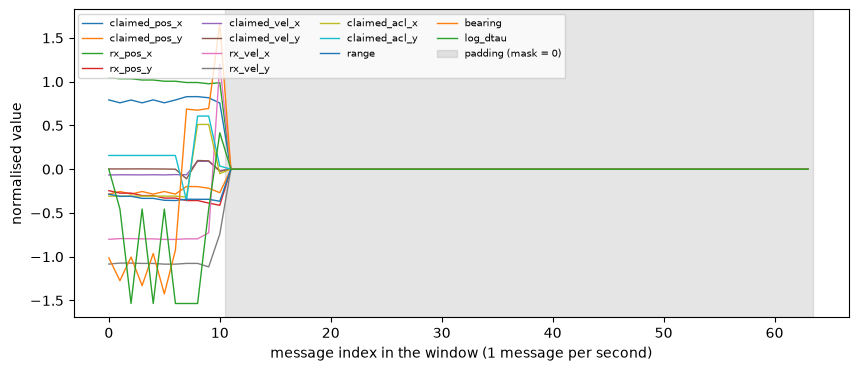

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for j, name in enumerate(FEATURES):
    ax.plot(train["x"][example][:, j], label=name, lw=1)
ax.axvspan(n_real - 0.5, 63.5, color="grey", alpha=0.2, label="padding (mask = 0)")
ax.set(xlabel="message index in the window (1 message per second)", ylabel="normalised value")
ax.legend(ncol=4, fontsize=7, loc="upper left")
plt.show()

**Class counts.** We read the **train** labels now, because the autoencoder must be trained on benign windows only.
The **test** labels stay unread until every test window has a score (section 8), so no choice can be tuned on them.

In [10]:
train_labels = read_labels("train")  # used to pick benign windows and to train the supervised baseline
counts = pd.Series(train_labels).map({0: "benign", 1: "GridSybil"}).value_counts()
print(counts.to_string())
print(f"GridSybil share in train: {train_labels.mean():.1%}")

GridSybil    217928
benign       120073
GridSybil share in train: 64.5%


## 4. Split by vehicle

We need a **validation** set to decide when to stop training. It must not share a car with the training part, or
the model could memorise a car and look better than it is. So we hold out **10% of the sender vehicles** (seed 0):
all windows of a chosen vehicle go to validation, all others to "fit" (the part we train on).

In [11]:
def split_by_vehicle(vehicles: np.ndarray, frac: float, seed: int) -> tuple[np.ndarray, np.ndarray]:
    """Row numbers (fit, val); each vehicle lands entirely on one side."""
    unique = np.unique(vehicles)
    rng = np.random.default_rng(seed)
    held_out = rng.permutation(unique)[: max(1, int(round(frac * len(unique))))]
    is_val = np.isin(vehicles, held_out)
    return np.flatnonzero(~is_val), np.flatnonzero(is_val)


def take(data: dict, rows: np.ndarray) -> dict:
    """The same dict with only the given rows."""
    return {key: value[rows] for key, value in data.items()}

For the autoencoder we keep only the **benign** train windows and split *their* vehicles.

In [12]:
benign_train = take(train, np.flatnonzero(train_labels == 0))
fit_rows, val_rows = split_by_vehicle(benign_train["vehicle"], SETTINGS.val_frac, SETTINGS.split_seed)
ae_fit, ae_val = take(benign_train, fit_rows), take(benign_train, val_rows)
assert not set(ae_fit["vehicle"]) & set(ae_val["vehicle"]), "fit and validation share a vehicle"
print(f"fit: {len(fit_rows):,} benign windows from {len(set(ae_fit['vehicle'])):,} vehicles")
print(f"val: {len(val_rows):,} benign windows from {len(set(ae_val['vehicle'])):,} vehicles")

fit: 107,924 benign windows from 3,263 vehicles
val: 12,149 benign windows from 362 vehicles


## 5. The autoencoder

An autoencoder has two halves:

- the **encoder** squeezes a window (64 x 13 + mask) into **z**, 16 numbers;
- the **decoder** tries to rebuild the 64 x 13 window from those 16 numbers.

Because 16 numbers cannot hold everything, the network has to learn what "typical" benign windows look like.

The layers are **1D convolutions** (`Conv1d`): a small filter that slides along time and looks at 3 neighbouring
messages at once. `stride 2` halves the length (64 -> 32 -> 16). `BatchNorm` keeps values in a stable range and
`ReLU` (max(0, v)) lets the network bend. The mask is given as a 14th input channel so the network knows which rows
are padding. The decoder mirrors the encoder with `ConvTranspose1d` layers that double the length again.

In [13]:
class Encoder(nn.Module):
    """(B, 64, 13) + mask (B, 64) -> z (B, 16)."""

    def __init__(self, latent_dim: int) -> None:
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(14, 32, 3, stride=1, padding=1),  # 13 features + 1 mask channel
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Conv1d(32, 64, 3, stride=2, padding=1),  # length 64 -> 32
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Conv1d(64, 64, 3, stride=2, padding=1),  # length 32 -> 16
            nn.BatchNorm1d(64),
            nn.ReLU(),
        )
        self.fc = nn.Linear(64 * 16, latent_dim)

    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        m = mask.unsqueeze(-1).float()
        h = torch.cat([x * m, m], dim=-1)  # (B, 64, 14)
        h = self.conv(h.transpose(1, 2))  # Conv1d wants (B, channels, time)
        return self.fc(h.flatten(1))

The **decoder** goes the other way: 16 numbers -> 64 x 16 -> 64 x 32 -> 64 x 64 -> 64 rows x 13 features.

In [14]:
class Decoder(nn.Module):
    """z (B, 16) -> reconstruction (B, 64, 13)."""

    def __init__(self, latent_dim: int) -> None:
        super().__init__()
        self.fc = nn.Linear(latent_dim, 64 * 16)
        self.deconv = nn.Sequential(
            nn.ReLU(),
            nn.ConvTranspose1d(64, 64, 4, stride=2, padding=1),  # length 16 -> 32
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.ConvTranspose1d(64, 32, 4, stride=2, padding=1),  # length 32 -> 64
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Conv1d(32, 13, 3, stride=1, padding=1),  # back to 13 features
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        h = self.fc(z).view(-1, 64, 16)
        return self.deconv(h).transpose(1, 2)  # (B, 64, 13)

The **autoencoder** simply chains the two. `count_params` counts the trainable numbers.

In [15]:
class Autoencoder(nn.Module):
    """Encoder + decoder. `forward` returns the reconstruction (B, 64, 13)."""

    def __init__(self, latent_dim: int) -> None:
        super().__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        return self.decoder(self.encoder(x, mask))


def count_params(model: nn.Module) -> int:
    """Number of trainable numbers (weights and biases)."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

The table below sends two dummy windows through the network and prints the output shape of every layer, so you can
follow 64 x 14 -> 16 numbers -> 64 x 13. The parameter count must equal the reference model's 80,189.

In [16]:
def layer_table(model: nn.Module, x: torch.Tensor, mask: torch.Tensor) -> pd.DataFrame:
    """Output shape and parameter count of every layer for one forward pass."""
    names = {layer: name for name, layer in model.named_modules() if len(list(layer.children())) == 0}
    rows, hooks = [], []

    def record(layer, inputs, output):
        rows.append(
            {
                "layer": names[layer],
                "type": type(layer).__name__,
                "output shape": tuple(output.shape),
                "params": count_params(layer),
            }
        )

    for layer in names:  # only the innermost layers
        hooks.append(layer.register_forward_hook(record))
    with torch.no_grad():
        model.eval()(x, mask)
    for hook in hooks:
        hook.remove()
    return pd.DataFrame(rows)

We build the autoencoder (with seed 0, so it starts from the same weights as the reference run) and print the table.

In [17]:
torch.manual_seed(SETTINGS.seed)  # same starting weights as the reference run
autoencoder = Autoencoder(SETTINGS.latent_dim)
print(layer_table(autoencoder, torch.zeros(2, 64, 13), torch.ones(2, 64, dtype=torch.bool)).to_string(index=False))
n_ae_params = count_params(autoencoder)
print(f"\ntrainable parameters: {n_ae_params:,}")
assert n_ae_params == 80_189, "the architecture differs from task/encoder/model.py"

           layer            type output shape  params
  encoder.conv.0          Conv1d  (2, 32, 64)    1376
  encoder.conv.1     BatchNorm1d  (2, 32, 64)      64
  encoder.conv.2            ReLU  (2, 32, 64)       0
  encoder.conv.3          Conv1d  (2, 64, 32)    6208
  encoder.conv.4     BatchNorm1d  (2, 64, 32)     128
  encoder.conv.5            ReLU  (2, 64, 32)       0
  encoder.conv.6          Conv1d  (2, 64, 16)   12352
  encoder.conv.7     BatchNorm1d  (2, 64, 16)     128
  encoder.conv.8            ReLU  (2, 64, 16)       0
      encoder.fc          Linear      (2, 16)   16400
      decoder.fc          Linear    (2, 1024)   17408
decoder.deconv.0            ReLU  (2, 64, 16)       0
decoder.deconv.1 ConvTranspose1d  (2, 64, 32)   16448
decoder.deconv.2     BatchNorm1d  (2, 64, 32)     128
decoder.deconv.3            ReLU  (2, 64, 32)       0
decoder.deconv.4 ConvTranspose1d  (2, 32, 64)    8224
decoder.deconv.5     BatchNorm1d  (2, 32, 64)      64
decoder.deconv.6            

## 6. The loss: masked mean squared error

The **loss** is the number training tries to make small. Here it is the **mean squared error** (MSE) between the
window and its reconstruction: the average of (rebuilt value - true value)^2. We average **only over real rows**;
padding rows are left out, otherwise the network could look good just by outputting zeros on the padding.

We also need a **per-window** version: the error of one window is our attack score.

In [18]:
def masked_mse(recon: torch.Tensor, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    """One number: mean squared error over all real rows and all 13 features of a batch."""
    m = mask.unsqueeze(-1).float()
    return ((recon - x) ** 2 * m).sum() / (m.sum() * x.shape[-1]).clamp_min(1.0)


def window_errors(recon: torch.Tensor, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    """One number per window: its mean squared error over its real rows and all features."""
    m = mask.unsqueeze(-1).float()
    per_feature = ((recon - x) ** 2 * m).sum(dim=1) / m.sum(dim=1).clamp_min(1.0)
    return per_feature.mean(dim=1)

**A tiny worked example.** One window with 3 rows and 1 feature (to keep the arithmetic short). The true values are
1, 2 and 0, the reconstruction is 1.5, 2 and 9, and the last row is padding. Only the two real rows count:
((1.5 - 1)^2 + (2 - 2)^2) / 2 = 0.25 / 2 = **0.125**. The huge mistake on the padding row (9 instead of 0) is ignored.

In [19]:
x_tiny = torch.tensor([[[1.0], [2.0], [0.0]]])  # (1 window, 3 rows, 1 feature)
recon_tiny = torch.tensor([[[1.5], [2.0], [9.0]]])
mask_tiny = torch.tensor([[True, True, False]])
print("masked MSE:", masked_mse(recon_tiny, x_tiny, mask_tiny).item())
print("per-window error:", window_errors(recon_tiny, x_tiny, mask_tiny).tolist())

masked MSE: 0.125
per-window error: [0.125]


## 7. Train on benign windows only

Training in plain words:

- An **epoch** is one pass over all fit windows, in random order, in **batches** of 256.
- For each batch: compute the loss, compute how each weight should change to lower it (`backward`), and let the
  **Adam** optimiser change the weights a little (learning rate 1e-3; weight decay 1e-5 is a tiny pull toward small
  weights).
- After each epoch we measure the loss on the **validation** windows, which the model never trains on.
- If the validation loss has not improved for more than 3 epochs in a row (so on the 4th), the learning rate is
  halved (`ReduceLROnPlateau`).
- If it has not improved for 5 epochs, we stop (**early stopping**) and go back to the best weights.

The same three functions are reused later for the supervised model; only the loss function changes. A loss function
here takes `(model, x, mask, y)` and returns one number.

In [20]:
def to_device(data: dict, y: np.ndarray | None = None) -> tuple:
    """(x, mask, y) as tensors on the device; y is None for the autoencoder."""
    x = torch.from_numpy(data["x"]).to(DEVICE)
    mask = torch.from_numpy(data["mask"]).to(DEVICE)
    return x, mask, None if y is None else torch.from_numpy(y.astype(np.float32)).to(DEVICE)


def train_one_epoch(model, loss_fn, optimizer, data: tuple, generator: torch.Generator) -> float:
    """One pass over the fit windows in random batches; returns the mean batch loss."""
    x, mask, y = data
    model.train()
    order = torch.randperm(len(x), generator=generator).to(DEVICE)
    losses = []
    for start in range(0, len(x), SETTINGS.batch_size):
        rows = order[start : start + SETTINGS.batch_size]
        if len(rows) < 2:  # BatchNorm needs at least 2 windows
            continue
        loss = loss_fn(model, x[rows], mask[rows], None if y is None else y[rows])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return float(np.mean(losses))

`validation_loss` measures the loss on the validation windows without changing any weight (`no_grad`). For the
autoencoder each batch is weighted by its number of real rows, so the result is the masked MSE over all of them.

In [21]:
@torch.no_grad()
def validation_loss(model, loss_fn, data: tuple, weight_by_rows: bool) -> float:
    """Loss over all validation windows, in big batches (weighted by real rows for the autoencoder)."""
    x, mask, y = data
    model.eval()
    total, weight = 0.0, 0.0
    for start in range(0, len(x), SETTINGS.eval_batch):
        part = slice(start, start + SETTINGS.eval_batch)
        w = float(mask[part].sum()) if weight_by_rows else float(len(x[part]))
        total += loss_fn(model, x[part], mask[part], None if y is None else y[part]).item() * w
        weight += w
    return total / weight

`epoch_row` prints one line per epoch and returns the numbers for the history (used for the loss curve).

In [22]:
def epoch_row(epoch: int, train_loss: float, val_loss: float, lr: float, improved: bool) -> dict:
    """Prints one epoch's losses (`*` = new best validation loss) and returns them as a dict."""
    print(f"epoch {epoch:3d}  train {train_loss:.5f}  val {val_loss:.5f}  lr {lr:.1e} {'*' if improved else ''}")
    return {"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "lr": lr}

`train_with_early_stopping` is the whole training: epochs until the validation loss stops improving.

In [23]:
def train_with_early_stopping(model, loss_fn, fit: tuple, val: tuple, weight_by_rows: bool) -> list[dict]:
    """Adam + ReduceLROnPlateau + early stopping; leaves the best weights in `model`, returns the history."""
    optimizer = torch.optim.Adam(model.parameters(), lr=SETTINGS.lr, weight_decay=SETTINGS.weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=SETTINGS.plateau_factor, patience=SETTINGS.plateau_patience
    )
    generator = torch.Generator().manual_seed(SETTINGS.seed)
    history, best, best_weights, waited = [], float("inf"), None, 0
    for epoch in range(1, SETTINGS.max_epochs + 1):
        train_loss = train_one_epoch(model, loss_fn, optimizer, fit, generator)
        val_loss = validation_loss(model, loss_fn, val, weight_by_rows)
        scheduler.step(val_loss)
        improved = val_loss < best
        if improved:
            best, waited = val_loss, 0
            best_weights = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
        history.append(epoch_row(epoch, train_loss, val_loss, optimizer.param_groups[0]["lr"], improved))
        if waited >= SETTINGS.patience:
            break
    model.load_state_dict(best_weights)
    return history

Now we train the autoencoder. Each printed line is one epoch; `*` marks a new best validation loss. This takes a few
minutes (the reference seed-0 run stopped after 121 epochs).

In [24]:
def reconstruction_loss(model, x, mask, y):
    """Autoencoder loss: masked MSE between the window and its reconstruction (y is not used)."""
    return masked_mse(model(x, mask), x, mask)


autoencoder = autoencoder.to(DEVICE)
started = time.time()
ae_history = train_with_early_stopping(
    autoencoder, reconstruction_loss, to_device(ae_fit), to_device(ae_val), weight_by_rows=True
)
ae_minutes = (time.time() - started) / 60
ae_best = min(ae_history, key=lambda row: row["val_loss"])
print(f"\nstopped after {len(ae_history)} epochs ({ae_minutes:.1f} min)")
print(f"best epoch {ae_best['epoch']}, validation loss {ae_best['val_loss']:.5f}")

epoch   1  train 0.34058  val 0.22190  lr 1.0e-03 *


epoch   2  train 0.20846  val 0.19651  lr 1.0e-03 *


epoch   3  train 0.18918  val 0.18265  lr 1.0e-03 *


epoch   4  train 0.17853  val 0.17561  lr 1.0e-03 *


epoch   5  train 0.17144  val 0.16916  lr 1.0e-03 *


...

epoch 117  train 0.11059  val 0.12103  lr 6.3e-05 


epoch 118  train 0.11056  val 0.12094  lr 6.3e-05 


epoch 119  train 0.11050  val 0.12100  lr 6.3e-05 


epoch 120  train 0.11050  val 0.12089  lr 3.1e-05 


epoch 121  train 0.11020  val 0.12091  lr 3.1e-05 

stopped after 121 epochs (4.1 min)
best epoch 116, validation loss 0.12086


The **loss curve**: both losses should fall and then flatten. If the validation loss rose while the training loss
kept falling, the model would be memorising the fit windows (overfitting); early stopping guards against that.

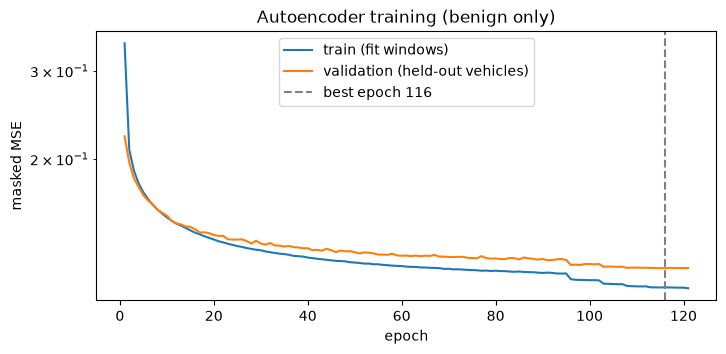

In [25]:
epochs = [row["epoch"] for row in ae_history]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(epochs, [row["train_loss"] for row in ae_history], label="train (fit windows)")
ax.plot(epochs, [row["val_loss"] for row in ae_history], label="validation (held-out vehicles)")
ax.axvline(ae_best["epoch"], color="grey", ls="--", label=f"best epoch {ae_best['epoch']}")
ax.set(xlabel="epoch", ylabel="masked MSE", yscale="log", title="Autoencoder training (benign only)")
ax.legend()
plt.show()

## 8. Score the test windows

Every window now gets a score = its **reconstruction error**. To turn a score into a yes / no decision we need a
**threshold**. We take it from the **validation benign** windows only: the 95th percentile (5% of benign windows are
above it, so we expect about 5% false alarms) and the 99th percentile (about 1%). No attack window is used to set it.

In [26]:
@torch.no_grad()
def score_reconstruction(model, data: dict) -> np.ndarray:
    """Reconstruction error of every window, in big batches."""
    model.eval()
    errors = []
    for start in range(0, len(data["x"]), SETTINGS.eval_batch):
        x = torch.from_numpy(data["x"][start : start + SETTINGS.eval_batch]).to(DEVICE)
        mask = torch.from_numpy(data["mask"][start : start + SETTINGS.eval_batch]).to(DEVICE)
        errors.append(window_errors(model(x, mask), x, mask).cpu().numpy())
    return np.concatenate(errors)


val_errors = score_reconstruction(autoencoder, ae_val)
thresholds = {"p95": float(np.percentile(val_errors, 95)), "p99": float(np.percentile(val_errors, 99))}
test_errors = score_reconstruction(autoencoder, test)
print("thresholds from validation benign errors:", {k: round(v, 4) for k, v in thresholds.items()})

thresholds from validation benign errors: {'p95': 0.388, 'p99': 0.59}


Every test window has a score now, so this is the first moment we read the **test labels**.

In [27]:
assert len(test_errors) == len(test["x"]), "not every test window has a score"
test_labels = read_labels("test")  # evaluation only, after the scores exist
print(pd.Series(test_labels).map({0: "benign", 1: "GridSybil"}).value_counts().to_string())
print(f"GridSybil share in test: {test_labels.mean():.1%} (a score that guesses has PR-AUC = this share)")

GridSybil    25685
benign       12741
GridSybil share in test: 66.8% (a score that guesses has PR-AUC = this share)


## 9. How good is it?

GridSybil is the **positive** class. The measures:

- **AUROC**: pick one benign and one GridSybil window at random; AUROC is the chance the GridSybil one has the higher
  score. 0.5 = guessing, 1.0 = perfect. It needs no threshold.
- **PR-AUC** (average precision): how precise the alarms are, averaged over all thresholds. Guessing gives the
  GridSybil share (0.668 here), not 0.5.
- At a threshold: **precision** = share of alarms that are real attacks; **recall** = share of attacks caught;
  **F1** = their harmonic mean; **FPR** = share of benign windows wrongly flagged. The **confusion matrix** counts
  true negatives (TN), false positives (FP), false negatives (FN) and true positives (TP).

In [28]:
def threshold_metrics(labels: np.ndarray, scores: np.ndarray, threshold: float) -> dict:
    """Precision, recall, F1, FPR and the confusion matrix for `score >= threshold` = GridSybil."""
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return {
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "fpr": fp / max(fp + tn, 1),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }

`summarise` collects, for one score, the measures that need no threshold (AUROC, PR-AUC) and the measures at each
named threshold.

In [29]:
def summarise(labels: np.ndarray, scores: np.ndarray, thresholds: dict) -> dict:
    """AUROC, PR-AUC and the metrics at every named threshold."""
    return {
        "auroc": float(roc_auc_score(labels, scores)),
        "pr_auc": float(average_precision_score(labels, scores)),
        "at_threshold": {name: threshold_metrics(labels, scores, t) for name, t in thresholds.items()},
    }

The autoencoder's results on the test split; the table has one row per threshold (the four counts are numbers of test windows).

In [30]:
ae_result = summarise(test_labels, test_errors, thresholds)
print(f"AE reconstruction error: AUROC {ae_result['auroc']:.3f}, PR-AUC {ae_result['pr_auc']:.3f}")
pd.DataFrame.from_dict(ae_result["at_threshold"], orient="index").round(3)

AE reconstruction error: AUROC 0.655, PR-AUC 0.801


,threshold,precision,recall,f1,fpr,TN,FP,FN,TP
p95,0.388,0.887,0.194,0.318,0.050,12109,632,20711,4974
p99,0.590,0.946,0.103,0.185,0.012,12592,149,23051,2634


The **histogram** shows the two classes' error distributions (log scale, each class scaled to area 1) and the two
thresholds. Where the coloured areas overlap, no threshold can separate the classes.

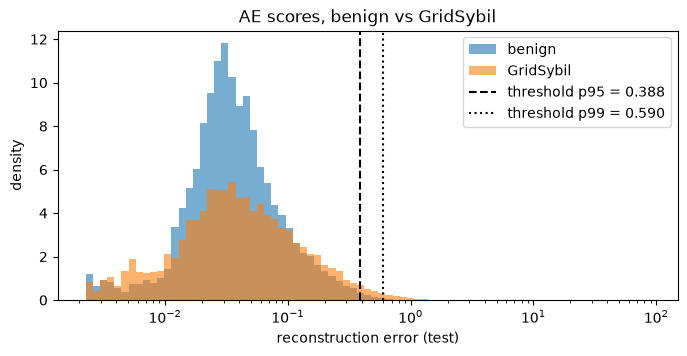

In [31]:
bins = np.logspace(np.log10(test_errors.min() + 1e-6), np.log10(test_errors.max()), 80)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(test_errors[test_labels == 0], bins=bins, density=True, alpha=0.6, label="benign")
ax.hist(test_errors[test_labels == 1], bins=bins, density=True, alpha=0.6, label="GridSybil")
for name, value in thresholds.items():
    ax.axvline(value, color="black", ls="--" if name == "p95" else ":", label=f"threshold {name} = {value:.3f}")
ax.set(xscale="log", xlabel="reconstruction error (test)", ylabel="density", title="AE scores, benign vs GridSybil")
ax.legend()
plt.show()

The **ROC curve** plots the share of attacks caught (true positive rate) against the share of benign windows flagged
(false positive rate) for every possible threshold. The area under it is the AUROC; the diagonal is guessing.

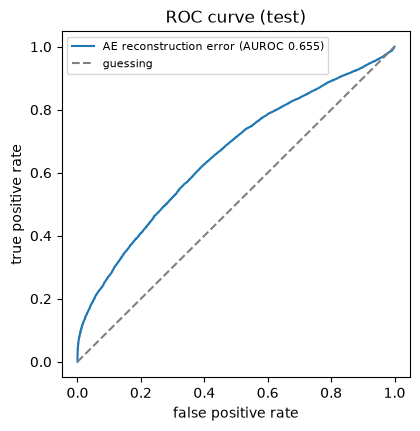

In [32]:
fpr, tpr, _ = roc_curve(test_labels, test_errors)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(fpr, tpr, label=f"AE reconstruction error (AUROC {ae_result['auroc']:.3f})")
ax.plot([0, 1], [0, 1], color="grey", ls="--", label="guessing")
ax.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve (test)")
ax.legend(fontsize=8)
plt.show()

## 10. Supervised baseline

Now the same encoder **with the labels**: after the encoder we put a small "head" (16 -> 32 -> 1 numbers) that
outputs a **logit**; the sigmoid of it is the probability of GridSybil. It is trained on **all** train windows with
**binary cross-entropy** (BCE), the standard loss for yes / no questions. There are more GridSybil than benign windows,
so the GridSybil term is weighted by benign / GridSybil (`pos_weight`) to balance the classes. Validation = 10% of all
train sender vehicles. This model shows what the encoder can do when it is told what to look for; it is not one-class.

In [33]:
class SupervisedModel(nn.Module):
    """The same encoder + a head 16 -> 32 -> 1. `forward` returns one logit per window."""

    def __init__(self, latent_dim: int) -> None:
        super().__init__()
        self.encoder = Encoder(latent_dim)
        self.head = nn.Sequential(nn.Linear(latent_dim, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        return self.head(self.encoder(x, mask)).squeeze(-1)


torch.manual_seed(SETTINGS.seed)
supervised = SupervisedModel(SETTINGS.latent_dim).to(DEVICE)
n_sup_params = count_params(supervised)
print(f"trainable parameters: {n_sup_params:,}")
assert n_sup_params == 37_233, "the architecture differs from task/encoder/model.py"

trainable parameters: 37,233


The supervised validation split holds out 10% of **all** train sender vehicles (both classes). `pos_weight` =
benign / GridSybil windows in the fit part.

In [34]:
fit_rows, val_rows = split_by_vehicle(train["vehicle"], SETTINGS.val_frac, SETTINGS.split_seed)
sup_fit, sup_val = take(train, fit_rows), take(train, val_rows)
sup_fit_y, sup_val_y = train_labels[fit_rows], train_labels[val_rows]
assert not set(sup_fit["vehicle"]) & set(sup_val["vehicle"]), "fit and validation share a vehicle"
POS_WEIGHT = torch.tensor((len(sup_fit_y) - sup_fit_y.sum()) / sup_fit_y.sum(), dtype=torch.float32, device=DEVICE)
print(f"fit {len(fit_rows):,} windows, val {len(val_rows):,} windows, pos_weight {POS_WEIGHT.item():.4f}")


def bce_loss(model, x, mask, y):
    """Supervised loss: class-weighted binary cross-entropy on the logit."""
    return nn.functional.binary_cross_entropy_with_logits(model(x, mask), y, pos_weight=POS_WEIGHT)

fit 304,733 windows, val 33,268 windows, pos_weight 0.5475


Training uses the same loop as the autoencoder, with the BCE loss. It stops much earlier (the reference: 19 epochs).

In [35]:
started = time.time()
sup_history = train_with_early_stopping(
    supervised, bce_loss, to_device(sup_fit, sup_fit_y), to_device(sup_val, sup_val_y), weight_by_rows=False
)
sup_minutes = (time.time() - started) / 60
print(f"\nstopped after {len(sup_history)} epochs ({sup_minutes:.1f} min)")

epoch   1  train 0.23416  val 0.21709  lr 1.0e-03 *


epoch   2  train 0.21107  val 0.21332  lr 1.0e-03 *


epoch   3  train 0.20782  val 0.21198  lr 1.0e-03 *


epoch   4  train 0.20512  val 0.21007  lr 1.0e-03 *


epoch   5  train 0.20283  val 0.20687  lr 1.0e-03 *


...

epoch  15  train 0.17279  val 0.20015  lr 1.0e-03 


epoch  16  train 0.17056  val 0.20492  lr 1.0e-03 


epoch  17  train 0.16914  val 0.20303  lr 1.0e-03 


epoch  18  train 0.16778  val 0.20187  lr 5.0e-04 


epoch  19  train 0.16013  val 0.20675  lr 5.0e-04 

stopped after 19 epochs (1.1 min)


Its score is the predicted probability; the usual threshold is 0.5.

In [36]:
@torch.no_grad()
def score_probability(model, data: dict) -> np.ndarray:
    """P(GridSybil) of every window."""
    model.eval()
    probs = []
    for start in range(0, len(data["x"]), SETTINGS.eval_batch):
        x = torch.from_numpy(data["x"][start : start + SETTINGS.eval_batch]).to(DEVICE)
        mask = torch.from_numpy(data["mask"][start : start + SETTINGS.eval_batch]).to(DEVICE)
        probs.append(torch.sigmoid(model(x, mask)).cpu().numpy())
    return np.concatenate(probs)


test_probs = score_probability(supervised, test)
sup_result = summarise(test_labels, test_probs, {"p0.5": 0.5})
print(f"supervised: AUROC {sup_result['auroc']:.3f}, PR-AUC {sup_result['pr_auc']:.3f}")
pd.DataFrame.from_dict(sup_result["at_threshold"], orient="index").round(3)

supervised: AUROC 0.926, PR-AUC 0.970


,threshold,precision,recall,f1,fpr,TN,FP,FN,TP
p0.5,0.5,0.991,0.804,0.888,0.014,12563,178,5046,20639


## 11. Shortcut baselines

A model can look good for a boring reason. Two cheap baselines check that:

- **Length only**: the score is the number of real messages in the window. Its direction (are GridSybil windows
  shorter or longer?) is picked on the test labels, which can only make this baseline look *better* than it is.

In [37]:
length_auroc = roc_auc_score(test_labels, test["n_messages"])
length_sign = 1 if length_auroc >= 0.5 else -1  # -1 means "shorter = GridSybil"
length_scores = length_sign * test["n_messages"].astype(float)
length_result = summarise(test_labels, length_scores, {})
print(f"length only ({'+' if length_sign > 0 else '-'}n_messages): AUROC {length_result['auroc']:.3f}")

length only (-n_messages): AUROC 0.535


- **Simple statistics + logistic regression**: for every feature, the mean, standard deviation, minimum and maximum
  over the real rows, plus the length: 4 x 13 + 1 = 53 numbers per window. They are standardised (mean 0, std 1) and
  fed to a **logistic regression** (a linear model that outputs a probability), trained on the train split with
  balanced class weights.

In [38]:
def window_statistics(x: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """(N, 53): per-feature mean, std, min, max over real rows, then the number of real rows."""
    real = mask[:, :, None]
    n = mask.sum(axis=1).astype(np.float64)[:, None]
    mean = np.where(real, x, 0.0).sum(axis=1) / np.maximum(n, 1)
    std = np.sqrt(np.where(real, (x - mean[:, None, :]) ** 2, 0.0).sum(axis=1) / np.maximum(n, 1))
    low = np.where(real, x, np.inf).min(axis=1)
    high = np.where(real, x, -np.inf).max(axis=1)
    return np.concatenate([mean, std, low, high, n], axis=1)


stats_model = make_pipeline(
    StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=SETTINGS.seed)
)
stats_model.fit(window_statistics(train["x"], train["mask"]), train_labels)
stats_probs = stats_model.predict_proba(window_statistics(test["x"], test["mask"]))[:, 1]
stats_result = summarise(test_labels, stats_probs, {"p0.5": 0.5})
print(f"stats + logistic regression: AUROC {stats_result['auroc']:.3f}, PR-AUC {stats_result['pr_auc']:.3f}")

stats + logistic regression: AUROC 0.855, PR-AUC 0.926


## 12. Comparison

All four scores on the same test windows. An empty cell (`NaN`) means that method has no such threshold: p95 / p99
belong to the autoencoder, 0.5 to the two probability models, and length only has none.

In [39]:
results = {
    "AE reconstruction error (one-class)": ae_result,
    "Supervised encoder + head": sup_result,
    "Stats + logistic regression": stats_result,
    "Length only": length_result,
}
table = pd.DataFrame(
    {
        name: {"AUROC": r["auroc"], "PR-AUC": r["pr_auc"]}
        | {f"F1 @ {t}": m["f1"] for t, m in r["at_threshold"].items()}
        for name, r in results.items()
    }
).T
table.round(3)

,AUROC,PR-AUC,F1 @ p95,F1 @ p99,F1 @ p0.5
AE reconstruction error (one-class),0.655,0.801,0.318,0.185,NaN
Supervised encoder + head,0.926,0.970,NaN,NaN,0.888
Stats + logistic regression,0.855,0.926,NaN,NaN,0.849
Length only,0.535,0.699,NaN,NaN,NaN


The same AUROCs as a bar chart. The dashed line is guessing.

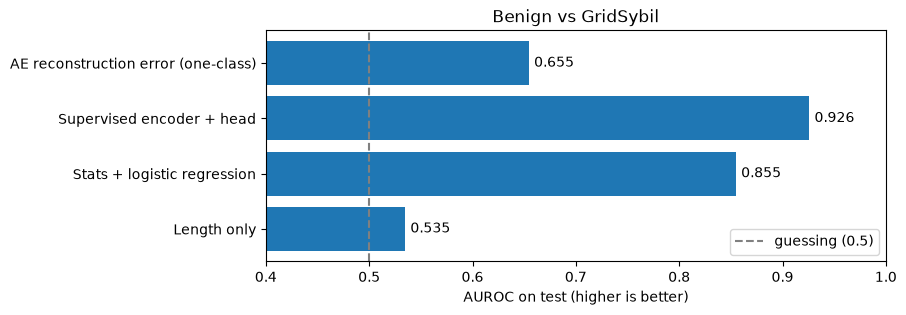

In [40]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(table.index[::-1], table["AUROC"][::-1], color="tab:blue")
ax.axvline(0.5, color="grey", ls="--", label="guessing (0.5)")
for i, value in enumerate(table["AUROC"][::-1]):
    ax.text(value + 0.005, i, f"{value:.3f}", va="center")
ax.set(xlim=(0.4, 1.0), xlabel="AUROC on test (higher is better)", title="Benign vs GridSybil")
ax.legend(loc="lower right")
plt.show()

## 13. Per window length

Short windows (1 to 3 messages) carry little information, long ones a lot. Here every method's AUROC is computed
inside each length group. The "length only" column is the AUROC of the length *inside* the group, in its better
direction, to check that length does not explain the result there either.

In [41]:
LENGTH_GROUPS = {"n <= 3": (1, 3), "4-16": (4, 16), "17-48": (17, 48), "49-64": (49, 64)}
scores = {"AE recon": test_errors, "supervised": test_probs, "stats LR": stats_probs}
rows = []
for group, (low, high) in LENGTH_GROUPS.items():
    inside = (test["n_messages"] >= low) & (test["n_messages"] <= high)
    y = test_labels[inside]
    length_auc = roc_auc_score(y, test["n_messages"][inside])
    row = {"group": group, "benign": int((y == 0).sum()), "GridSybil": int((y == 1).sum())}
    row["length only"] = max(length_auc, 1 - length_auc)
    rows.append(row | {name: roc_auc_score(y, s[inside]) for name, s in scores.items()})
strata = pd.DataFrame(rows).set_index("group")
strata.round(3)

,benign,GridSybil,length only,AE recon,supervised,stats LR
group,,,,,,
n <= 3,1822,4898,0.505,0.551,0.918,0.681
4-16,5236,10629,0.536,0.652,0.924,0.851
17-48,4452,7348,0.507,0.709,0.918,0.872
49-64,1231,2810,0.527,0.750,0.945,0.927


The same table as a chart.

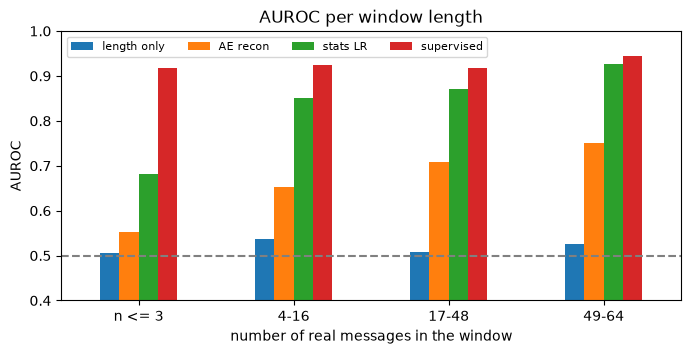

In [42]:
ax = strata[["length only", "AE recon", "stats LR", "supervised"]].plot.bar(figsize=(8, 3.5), rot=0)
ax.axhline(0.5, color="grey", ls="--")
ax.set(ylim=(0.4, 1.0), ylabel="AUROC", xlabel="number of real messages in the window", title="AUROC per window length")
ax.legend(fontsize=8, ncol=4, loc="upper left")
plt.show()

## 14. Save the run (reproducibility)

The settings, the seed, the software versions, the training histories and all results go to
`task/encoder/runs/notebook-seed0/` (gitignored), so this run can be compared and repeated later (RULE 4).

In [43]:
def git_commit() -> str:
    """Current git commit, or an empty string outside git."""
    try:
        return subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
    except (OSError, subprocess.CalledProcessError):
        return ""


environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "numpy": np.__version__,
    "sklearn": sklearn.__version__,
    "device": str(DEVICE),
    "git_commit": git_commit(),
    "finished": dt.datetime.now().isoformat(timespec="seconds"),
}
environment

{'python': '3.14.5 (main, May 10 2026, 10:21:34) [Clang 21.0.0 (clang-2100.0.123.102)]',
 'platform': 'macOS-26.4-arm64-arm-64bit-Mach-O',
 'torch': '2.14.1',
 'numpy': '2.5.3',
 'sklearn': '1.9.1',
 'device': 'mps',
 'git_commit': '14f1a37b74f245f8e25be1b7f902cd9d4e8420fd',
 'finished': '2026-10-27T12:38:57'}

Everything we measured goes into one dictionary, and the three files are written.

In [44]:
summary = {
    "ae": ae_result,
    "supervised": sup_result,
    "stats_lr": stats_result,
    "length": length_result,
    "length_direction": "+n_messages" if length_sign > 0 else "-n_messages",
    "thresholds_from_val_benign": thresholds,
    "strata_auroc": strata.to_dict(orient="index"),
    "n_params": {"autoencoder": n_ae_params, "supervised": n_sup_params},
    "epochs": {"autoencoder": len(ae_history), "supervised": len(sup_history)},
    "minutes": {"autoencoder": ae_minutes, "supervised": sup_minutes},
    "history": {"autoencoder": ae_history, "supervised": sup_history},
}
(OUT_DIR / "config.json").write_text(json.dumps(asdict(SETTINGS), indent=2))
(OUT_DIR / "env.json").write_text(json.dumps(environment, indent=2))
(OUT_DIR / "results.json").write_text(json.dumps(summary, indent=2, default=float))
print("saved to", OUT_DIR)

saved to task/encoder/runs/notebook-seed0


## 15. Compared with the reference (3 seeds)

The reference code (`task/encoder/*.py`) trained the same models with seeds 0, 1 and 2; its results are in
`task/encoder/runs/evaluation/results.json`. The table shows this notebook's seed 0 next to the reference seed 0 and
the reference mean +- standard deviation over the three seeds. Small differences come from GPU nondeterminism.

In [45]:
def compare_with_reference(reference_file: Path, mine: dict) -> pd.DataFrame:
    """AUROC of this notebook next to the reference seed 0 and the reference 3-seed mean and std."""
    reference = json.loads(reference_file.read_text())["methods"]
    rows = []
    for key, result in mine.items():
        ref = reference[key]
        seed0 = ref["per_seed"][0]["auroc"]
        rows.append(
            {
                "method": key,
                "this notebook (seed 0)": result["auroc"],
                "reference seed 0": seed0,
                "reference mean": ref["summary"]["auroc"]["mean"],
                "reference std": ref["summary"]["auroc"]["std"],
                "difference vs reference seed 0": result["auroc"] - seed0,
            }
        )
    return pd.DataFrame(rows).set_index("method")

The comparison itself (it needs the reference results; `npm run enc:eval` creates them).

In [46]:
reference_file = Path("task/encoder/runs/evaluation/results.json")
mine = {
    "ae:recon_error": ae_result,
    "supervised:supervised_prob": sup_result,
    "baseline:stats_lr": stats_result,
    "baseline:length": length_result,
}
compare_with_reference(reference_file, mine).round(4) if reference_file.exists() else "no reference results found"

,this notebook (seed 0),reference seed 0,reference mean,reference std,difference vs reference seed 0
method,,,,,
ae:recon_error,0.6546,0.6546,0.6554,0.0024,0.0000
supervised:supervised_prob,0.9259,0.9259,0.9275,0.0018,0.0000
baseline:stats_lr,0.8550,0.8549,0.8549,0.0000,0.0001
baseline:length,0.5348,0.5348,0.5348,0.0000,0.0000


## 16. What it means

The numbers in this paragraph are the outputs of this run (seed 0) above.

- **The one-class autoencoder is a weak detector.** AUROC **0.655** (PR-AUC 0.801, where guessing gives 0.668). It is
  above guessing and above the length shortcut (0.535), so it does pick up *something*. But at the 95th-percentile
  threshold it catches only **19%** of GridSybil windows (recall 0.194) for 5% false alarms, and at the 99th
  percentile only 10%.
- **It loses to simple statistics.** The mean / std / min / max of each feature plus a logistic regression reaches
  AUROC **0.855**, and it beats the autoencoder in every length group. The logistic regression uses labels, so it is
  not a one-class method, but it is a far cheaper model. What the autoencoder learned about "normal" benign windows
  separates the classes less well than 53 hand-made numbers.
- **With labels, the same small encoder works well.** The supervised model reaches AUROC **0.926** and F1 0.888 at
  0.5, the best in every length group, even on the 1-3-message windows (0.918, where the statistics give 0.681). So
  the encoder *can* represent the difference; training it only to rebuild benign windows does not make it find it.
- **Length is not the shortcut here.** Length alone gives 0.535 overall and 0.505-0.536 inside the length groups.
  The autoencoder gets better on longer windows (0.551 for n <= 3 up to 0.750 for 49-64): it simply has more to go on.
- **Same as the reference.** This notebook reproduces the reference seed-0 AUROCs to four decimals (stats LR differs by
  0.0001; section 15), so the
  three-seed numbers in `task/encoder/README.md` (AE 0.655 +- 0.002, supervised 0.928 +- 0.002) apply to it.
- **Limits.** One seed, one small architecture, no hyperparameter search, one data subset (benign + GridSybil, both
  time windows pooled). Absolute positions are inputs, so part of what the statistics and the supervised model use may
  be *where* a car is rather than *how* it moves; this is not tested here. This is a baseline for this folder's task,
  not a thesis result for the TimesNet encoder.

## 17. Glossary

- **Window**: up to 64 consecutive messages one car received from one sender, 13 features each, padded to 64 rows.
- **Mask**: 1 for a real row, 0 for a padding row.
- **Padding**: empty rows added so every window has 64 rows.
- **GridSybil**: an attack where one car invents fake vehicles and broadcasts their positions.
- **Autoencoder**: a network that compresses its input (encoder) and rebuilds it (decoder).
- **z / latent**: the 16 numbers the encoder compresses a window into.
- **Conv1d**: a small filter sliding along time; **stride 2** halves the length.
- **ConvTranspose1d**: the reverse of a strided convolution; doubles the length.
- **BatchNorm**: rescales values inside a batch to keep training stable.
- **ReLU**: max(0, v), the simplest non-linear function.
- **Parameter**: one trainable number (a weight or a bias).
- **Loss**: the number training tries to make small.
- **MSE**: mean squared error; **masked** = only real rows count.
- **BCE**: binary cross-entropy, the loss for yes / no predictions; **pos_weight** balances the two classes.
- **Logit / sigmoid**: the raw output of the head / the function that turns it into a probability between 0 and 1.
- **Epoch / batch**: one pass over the training windows / a group of 256 windows processed together.
- **Adam**: the optimiser that changes the weights; **learning rate**: how big each change is.
- **ReduceLROnPlateau**: halves the learning rate when validation stops improving.
- **Early stopping**: stop when validation has not improved for 5 epochs; keep the best weights.
- **Validation set**: held-out windows (from other vehicles) used to decide when to stop.
- **One-class**: trained on one class only (benign); attacks are never seen.
- **Threshold / percentile**: the cut-off score; the 95th percentile is the value 95% of benign validation errors are below.
- **AUROC, PR-AUC, precision, recall, F1, FPR, confusion matrix**: see section 9.
- **Logistic regression**: a linear model that outputs a probability.
- **Shortcut**: an easy cue (like window length) that separates classes for a reason unrelated to the attack itself.